# 07 – So sánh tổng hợp các mô hình

Gộp kết quả mà các notebook 04–07 đã lưu trong `outputs/metrics/` (bảng baseline do `python main.py evaluate --family baseline` tạo). **Mọi mô hình dùng chung một phép chia train/test và cùng tập đánh giá.**

- Top-N (K = 10): Precision, Recall, NDCG, HitRate (cao hơn tốt hơn). Phim liên quan = rating ≥ 4 trong tập test; ứng viên là mọi phim chưa xem trong train.
- Ngoài độ chính xác: Coverage (độ phủ catalog), Novelty (độ mới lạ), Diversity (đa dạng thể loại trong danh sách), tính trên Top-20.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import load_experiment, make_validation, run_model, save_metrics

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
files = ["baseline", "knn", "mf", "content_hybrid", "deep"]
res = pd.concat([pd.read_csv(RESULTS_DIR / "metrics" / f"{f}.csv") for f in files], ignore_index=True)
res.to_csv(RESULTS_DIR / "metrics" / "all_models.csv", index=False)
print(len(res), "mô hình"); res.Family.value_counts()

18 mô hình


Family
Baseline                6
Matrix Factorization    4
Deep learning           3
Collaborative (kNN)     2
Content-based           2
Hybrid                  1
Name: count, dtype: int64

## Bảng kết quả – Xếp hạng Top-10 (sắp theo NDCG@10)

Trả lời câu hỏi: *trong 10 phim gợi ý, có bao nhiêu phim user thật sự thích, và chúng nằm ở vị trí nào?* Đây là nhóm chỉ số quan trọng nhất với một hệ thống gợi ý.

**Quy ước tính** (`src/evaluation/metrics.py`):
- Danh sách gợi ý của user = các phim điểm cao nhất, **đã loại phim user chấm trong train**.
- Phim **liên quan** = phim trong tập test được user chấm **≥ 4** (`RELEVANT_RATING`).
- Precision/Recall/NDCG/HitRate lấy trung bình trên các user có ít nhất 1 phim liên quan trong test.

*Ví dụ dùng chung bên dưới:* user có **5** phim liên quan; danh sách 10 phim trúng ở **vị trí 1 và 4**.

**Precision@10** – tỉ lệ phim gợi ý đúng gu

$$\text{Precision@}K = \frac{\#\text{phim trúng trong top-}K}{K}$$

Ví dụ: 2/10 = **0.2**. Precision@10 ≈ 0.24 nghĩa là trung bình khoảng 2–3 trong 10 phim gợi ý là phim user đã xem và thích.

**Recall@10** – tỉ lệ phim yêu thích mà mô hình tìm ra được

$$\text{Recall@}K = \frac{\#\text{phim trúng trong top-}K}{\#\text{phim liên quan của user}}$$

Ví dụ: 2/5 = **0.4**. User có nhiều phim liên quan (ví dụ 100) thì Recall@10 tối đa chỉ 10/100 = 0.1, nên giá trị trung bình thường thấp.

**NDCG@10** (Normalized Discounted Cumulative Gain) – độ chính xác *có tính thứ tự*

$$\text{DCG@}K = \sum_{p=1}^{K} \frac{\text{hit}_p}{\log_2(p+1)}, \qquad \text{NDCG@}K = \frac{\text{DCG@}K}{\text{IDCG@}K}$$

- Trúng ở vị trí càng cao càng được nhiều điểm (trọng số 1, 0.63, 0.5, 0.43, … , 0.29 cho vị trí 1 → 10).
- IDCG là DCG lý tưởng (mọi phim liên quan xếp đầu danh sách, tối đa K phim), nên NDCG ∈ [0, 1].
- Ví dụ: DCG = 1 + 1/log₂5 = 1.431; IDCG = 1 + 0.631 + 0.5 + 0.431 + 0.387 = 2.949; NDCG = **0.485**.
- Là **chỉ số chính để chọn mô hình gợi ý**, vì người dùng thường chỉ xem vài phim đầu danh sách.

**HitRate@10** – tỉ lệ user được gợi ý trúng ít nhất 1 phim

$$\text{HitRate@}K = \frac{\#\text{user có} \ge 1 \text{ phim trúng trong top-}K}{\#\text{user}}$$

Ví dụ: user trên có giá trị **1**. HitRate@10 ≈ 0.8 nghĩa là 80% user nhận được ít nhất một gợi ý đúng gu; đây là chỉ số dễ giải thích nhất với người không chuyên.

*Lưu ý khi đọc:* phim user chưa từng xem bị tính là "không liên quan" dù có thể user sẽ thích, và test chỉ chứa 20% lịch sử của mỗi user. Vì vậy giá trị tuyệt đối **đánh giá thấp** mọi mô hình như nhau; nên dùng các chỉ số này để **so sánh tương đối** giữa các mô hình.

**FitTime_s:** thời gian huấn luyện (giây, trên GPU). Không phản ánh chất lượng gợi ý, nhưng quan trọng khi ứng dụng phải huấn luyện lại (ví dụ có user mới).

In [3]:
cols = ["Model", "Family", "Precision@10", "Recall@10", "NDCG@10", "HitRate@10", "Coverage@20", "Novelty@20",
        "Diversity@20", "FitTime_s"]
t2 = res.sort_values("NDCG@10", ascending=False)[cols]
t2.round(4).reset_index(drop=True)

,Model,Family,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,Novelty@20,Diversity@20,FitTime_s
0,NeuMF(f=128),Deep learning,0.2477,0.1693,0.2946,0.8135,0.4107,2.6258,0.6380,12.4956
1,BPR-MF(f=32),Deep learning,0.2293,0.1527,0.2711,0.7829,0.4903,2.6821,0.6355,7.8182
2,ImplicitALS(f=32),Matrix Factorization,0.2054,0.1690,0.2502,0.8220,0.5316,2.9809,0.6152,0.5840
3,Popularity(count),Baseline,0.1484,0.0862,0.1735,0.6064,0.0289,1.6693,0.7231,0.0949
4,AutoRec(h=300),Deep learning,0.1472,0.0855,0.1726,0.5928,0.1754,2.3833,0.7205,2.4664
5,PureSVD(f=30),Matrix Factorization,0.1032,0.0520,0.1262,0.4737,0.0988,2.8034,0.7886,1.2200
6,Popularity(weighted),Baseline,0.0834,0.0485,0.1010,0.4603,0.0237,2.5522,0.7770,0.1070
7,Hybrid(MF+ItemKNN+Content),Hybrid,0.0835,0.0503,0.1001,0.4618,0.2045,3.3630,0.6308,12.2646
8,ContentBased(genres+title),Content-based,0.0715,0.0441,0.0875,0.4269,0.0982,3.3239,0.5514,0.5935
9,ContentBased(genres),Content-based,0.0663,0.0404,0.0813,0.4071,0.0823,3.3312,0.5552,0.8668


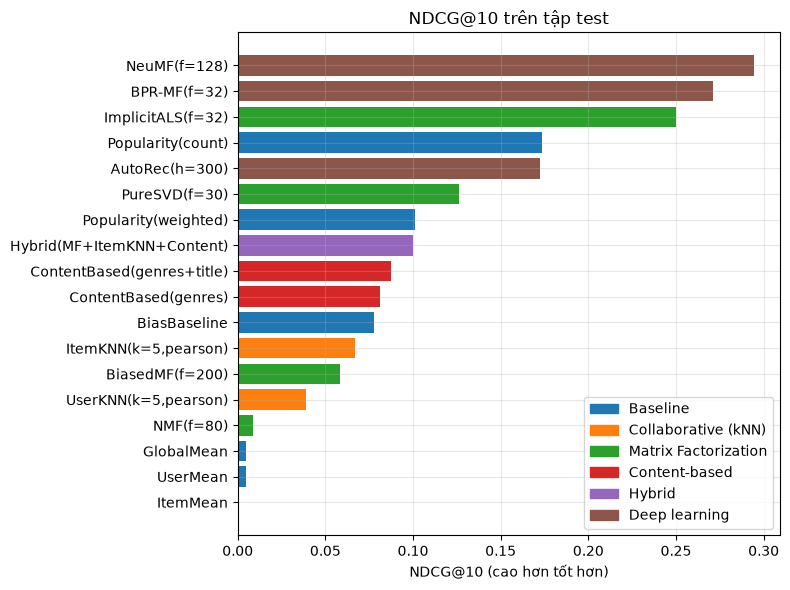

In [4]:
colors = dict(zip(res.Family.unique(), plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(8, 6))
d = t2.iloc[::-1]; ax.barh(d.Model, d["NDCG@10"], color=[colors[f] for f in d.Family])
ax.set(title="NDCG@10 trên tập test", xlabel="NDCG@10 (cao hơn tốt hơn)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "compare_ndcg.png"); plt.show()

## Ngoài độ chính xác: Coverage, Novelty, Diversity

Trả lời câu hỏi: *gợi ý có phong phú và đáng khám phá không, hay chỉ toàn phim bom tấn?* Tính trên danh sách **Top-20** của mọi user có trong test.

**Coverage@20** – độ phủ kho phim (cao hơn → dùng được nhiều phim hơn)

$$\text{Coverage@}K = \frac{\#\text{phim khác nhau xuất hiện trong danh sách của mọi user}}{\#\text{tổng số phim (3706)}}$$

- Popularity ≈ 0.03: mọi user nhận gần như cùng một danh sách (~100 phim). ItemKNN ≈ 0.84: gợi ý tới ~3.100 phim khác nhau.
- Coverage thấp nghĩa là phần lớn kho phim không bao giờ được gợi ý ("đuôi dài" bị bỏ quên).

**Novelty@20** – độ mới lạ (cao hơn → phim ít người biết hơn)

$$\text{Novelty@}K = \text{trung bình}\left[-\log_2 \text{pop}(i)\right], \qquad \text{pop}(i) = \frac{\#\text{user đã chấm phim } i \text{ (train)}}{\#\text{user}}$$

- Đổi ngược ra độ phổ biến trung bình: $\text{pop} \approx 2^{-\text{Novelty}}$. Novelty 2.4 → phim được ~19% user đã xem (phim nổi tiếng); Novelty 6.8 → ~0.9% (phim ít người biết).
- **Không phải cứ cao là tốt:** Novelty rất cao kèm NDCG gần 0 (ItemMean, NMF) nghĩa là mô hình gợi ý phim lạ *mà user không thích*. Novelty chỉ có giá trị khi độ chính xác vẫn ổn.

**Diversity@20** – đa dạng thể loại *bên trong một danh sách* (cao hơn → trộn nhiều thể loại)

$$\text{Diversity@}K = 1 - \frac{1}{K(K-1)} \sum_{i \ne j \in \text{top-}K} \cos(\mathbf{g}_i, \mathbf{g}_j)$$

với $\mathbf{g}_i$ là vector multi-hot 18 thể loại của phim $i$; lấy trung bình trên các user.
- ContentBased ≈ 0.55: gợi ý theo thể loại nên danh sách toàn phim cùng loại. BiasBaseline ≈ 0.79: danh sách trộn nhiều thể loại.
- Khác Coverage: Coverage đo đa dạng **giữa các user** (toàn hệ thống), Diversity đo đa dạng **trong danh sách của một user**.

**Đọc kết hợp các chỉ số:**

| Tình huống | Ý nghĩa |
|---|---|
| NDCG cao, Novelty/Coverage thấp | Gợi ý trúng gu nhưng thiên về phim nổi tiếng – an toàn, ít bất ngờ |
| NDCG khá + Coverage cao | Cân bằng giữa trúng gu và khai thác đa dạng kho phim |
| Novelty rất cao, NDCG ≈ 0 | Gợi ý phim lạ nhưng vô dụng |

In [5]:
res.set_index("Model")[["Coverage@20", "Novelty@20", "Diversity@20"]].round(3).sort_values("Coverage@20", ascending=False)

,Coverage@20,Novelty@20,Diversity@20
Model,,,
"ItemKNN(k=5,pearson)",0.849,3.981,0.713
"UserKNN(k=5,pearson)",0.686,3.695,0.728
ImplicitALS(f=32),0.532,2.981,0.615
BPR-MF(f=32),0.490,2.682,0.635
BiasedMF(f=200),0.476,4.736,0.725
NMF(f=80),0.436,7.413,0.657
NeuMF(f=128),0.411,2.626,0.638
Hybrid(MF+ItemKNN+Content),0.205,3.363,0.631
UserMean,0.187,6.510,0.743


## Kết luận

*Bài toán: xếp hạng danh sách gợi ý Top-N. Số liệu từ lần huấn luyện trên GPU (RTX 4060, PyTorch CUDA); mọi mô hình trừ nhóm Baseline tính toán trên GPU. Siêu tham số của mọi mô hình được chọn trên tập validation theo **NDCG@10**.*

- **Xếp hạng Top-N:** NeuMF f=128 (NDCG@10 ≈ 0.295) > BPR-MF f=32 (≈ 0.271) > Implicit ALS f=32 (≈ 0.250). Mốc không cá nhân hóa cần vượt qua là Popularity(count) (≈ 0.174): chỉ ba mô hình implicit này vượt rõ; AutoRec (≈ 0.173) xấp xỉ mốc, mọi mô hình còn lại đều thấp hơn mốc.
- **Nhất quán giữa validation và test:** thứ tự các mô hình dẫn đầu (NeuMF > BPR-MF > ALS > AutoRec > PureSVD) trên validation và trên test trùng nhau.
- **Hàm mục tiêu quan trọng hơn siêu tham số:** các mô hình được huấn luyện để khớp số sao trên ô đã chấm (kNN, BiasedMF, NMF, Content-based, Hybrid) dù đã dò theo NDCG@10 vẫn thấp hơn Popularity(count). Các mô hình học từ phản hồi implicit (ALS, BPR-MF, NeuMF) học trực tiếp "user sẽ thích phim nào" nên vượt xa. BPR-MF và BiasedMF cùng kiến trúc MF nhưng NDCG@10 chênh khoảng 5 lần.
- **Độ phủ/đa dạng:** Popularity chỉ gợi ý ~2–3% catalog. BPR-MF và ImplicitALS đạt độ phủ ~49–53% với NDCG cao; NeuMF chính xác nhất, độ phủ ~41%. ItemKNN phủ rộng nhất (~85%) nhưng NDCG thấp.
- **Chi phí (GPU):** mọi mô hình huấn luyện dưới 13 giây; chậm nhất là Hybrid, NeuMF f=128 và BiasedMF f=200 (10–13 giây).
- **Chọn mô hình cho ứng dụng:** NeuMF (f=128); BPR-MF là lựa chọn thay thế nếu muốn danh sách gợi ý đa dạng hơn.
- *Lưu ý:*
  - Một số cấu hình tốt nhất nằm ở biên lưới dò: kNN k=5, BiasedMF f=200, NMF f=80, NeuMF f=128. Tối ưu thật có thể nằm ngoài lưới; lưới được dừng ở mức hợp lý về chi phí và kích thước mô hình.
  - Kết quả từ một lần chia train/test với seed cố định. Huấn luyện trên GPU không hoàn toàn tất định nên số liệu có thể dao động nhẹ ở chữ số thứ 3–4.